# 💰 Financial Wellness Intelligence Platform
## EDA & Results Notebook — Review Presentation

**Three integrated ML engines:**
- 🎯 **Engine 1** — K-Means User Segmentation (5 Personas)
- 🔍 **Engine 2** — Subscription Leakage Detection & Scoring
- 📈 **Engine 3** — ARIMA + Prophet Wellness Forecasting

---

In [1]:
# ═══════════════════════════════════════════════════════════
# CELL 1: Imports & Load All Data
# ═══════════════════════════════════════════════════════════
import os, json, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# Notebook-inline rendering
%matplotlib inline
plt.rcParams.update({
    'figure.dpi':        150,
    'savefig.dpi':       150,
    'font.size':         10,
    'axes.titlesize':    12,
    'axes.titleweight':  'bold',
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'figure.facecolor':  '#f8f9fa',
    'axes.facecolor':    '#f8f9fa',
})
PALETTE = sns.color_palette('Set2', 10)

# ── Paths ────────────────────────────────────────────────
ROOT    = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA    = os.path.join(ROOT, 'data')
OUT     = os.path.join(ROOT, 'outputs')
NB_OUT  = os.path.join(ROOT, 'outputs')  # save PNGs here
os.makedirs(NB_OUT, exist_ok=True)

# ── Load all data ─────────────────────────────────────────
txn      = pd.read_csv(os.path.join(DATA, 'transactions_synthetic.csv'), parse_dates=['date'])
features = pd.read_csv(os.path.join(DATA, 'user_features.csv'), index_col='user_id')
clusters = pd.read_csv(os.path.join(DATA, 'user_clusters.csv'))
leakage  = pd.read_csv(os.path.join(DATA, 'user_leakage.csv'))
forecast = pd.read_csv(os.path.join(OUT,  'wellness_forecast_baseline.csv'))

with open(os.path.join(OUT, 'persona_insights.json')) as f:
    insights = json.load(f)

# ── Quick sanity check ────────────────────────────────────
datasets = {
    'transactions':   txn,
    'user_features':  features,
    'user_clusters':  clusters,
    'user_leakage':   leakage,
    'wellness_forecast': forecast,
}
print('╔══════════════════════════════════════════════════════╗')
print('║        FINANCIAL WELLNESS ENGINE — DATA SUMMARY      ║')
print('╠══════════════════════════════════════════════════════╣')
for name, df in datasets.items():
    print(f'║  {name:<24}  {df.shape[0]:>6,} rows × {df.shape[1]:>2} cols  ║')
print('╠══════════════════════════════════════════════════════╣')
print(f'║  Date range: {txn["date"].min().date()} → {txn["date"].max().date()}           ║')
print(f'║  Unique users:        {txn["user_id"].nunique():>4}                         ║')
print(f'║  Total spend:  ₹{txn[txn["transaction_type"]=="Debit"]["amount"].sum()/1e6:>6.2f}M                         ║')
print(f'║  Total income: ₹{txn[txn["transaction_type"]=="Credit"]["amount"].sum()/1e6:>6.2f}M                         ║')
print('╚══════════════════════════════════════════════════════╝')

╔══════════════════════════════════════════════════════╗
║        FINANCIAL WELLNESS ENGINE — DATA SUMMARY      ║
╠══════════════════════════════════════════════════════╣
║  transactions              10,000 rows ×  7 cols  ║
║  user_features                500 rows × 20 cols  ║
║  user_clusters                500 rows ×  3 cols  ║
║  user_leakage                 276 rows ×  9 cols  ║
║  wellness_forecast             30 rows ×  7 cols  ║
╠══════════════════════════════════════════════════════╣
║  Date range: 2025-09-21 → 2026-09-21           ║
║  Unique users:         500                         ║
║  Total spend:  ₹ 17.01M                         ║
║  Total income: ₹ 25.69M                         ║
╚══════════════════════════════════════════════════════╝


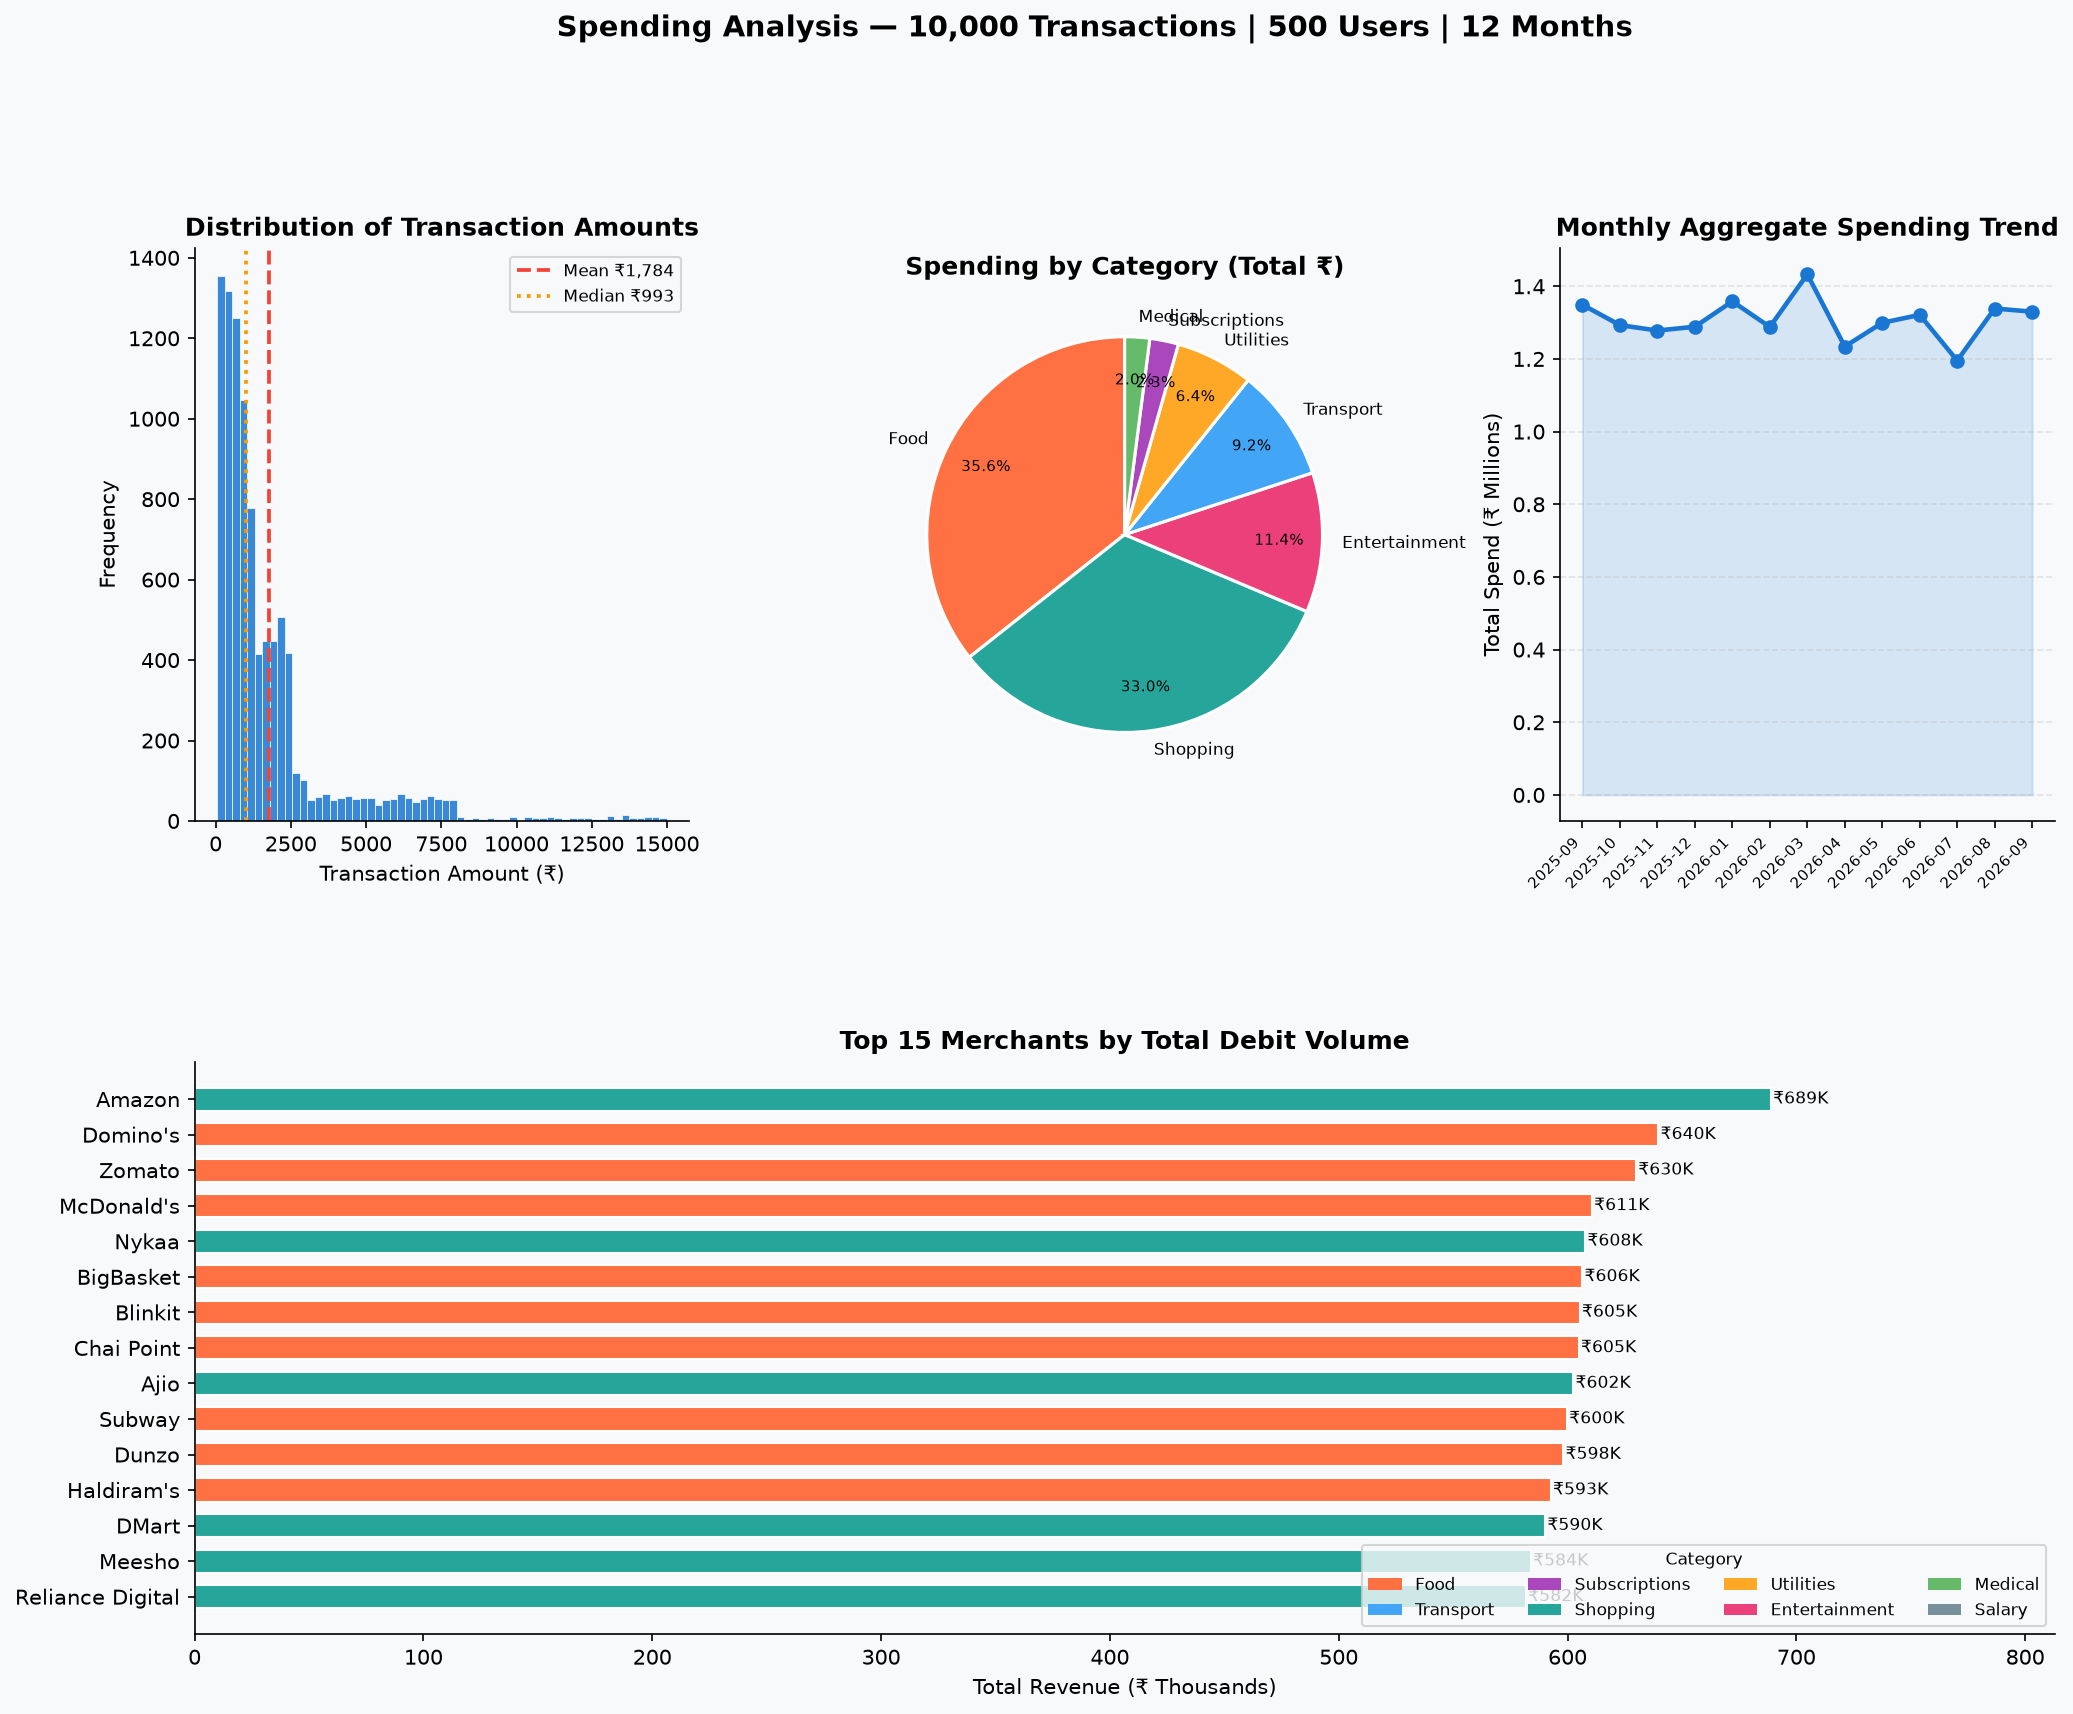

✅ Saved: outputs/eda_spending_analysis.png


In [2]:
# ═══════════════════════════════════════════════════════════
# CELL 2: Spending Analysis
# ═══════════════════════════════════════════════════════════
debits = txn[txn['transaction_type'] == 'Debit'].copy()

fig = plt.figure(figsize=(16, 12))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.42, wspace=0.38)

cat_colors = {
    'Food':          '#FF7043', 'Transport':     '#42A5F5',
    'Subscriptions': '#AB47BC', 'Shopping':      '#26A69A',
    'Utilities':     '#FFA726', 'Entertainment': '#EC407A',
    'Medical':       '#66BB6A', 'Salary':        '#78909C',
}

# ── 2a: Transaction amount histogram ─────────────────────
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(debits['amount'], bins=60, color='#1976D2', edgecolor='white',
         linewidth=0.4, alpha=0.85)
ax1.axvline(debits['amount'].mean(),   color='#F44336', lw=1.8,
            linestyle='--', label=f'Mean ₹{debits["amount"].mean():,.0f}')
ax1.axvline(debits['amount'].median(), color='#FF9800', lw=1.8,
            linestyle=':', label=f'Median ₹{debits["amount"].median():,.0f}')
ax1.set_xlabel('Transaction Amount (₹)')
ax1.set_ylabel('Frequency')
ax1.set_title('Distribution of Transaction Amounts')
ax1.legend(fontsize=8)

# ── 2b: Category spend pie ────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
cat_spend = debits.groupby('category')['amount'].sum().sort_values(ascending=False)
colors_pie = [cat_colors.get(c, '#90A4AE') for c in cat_spend.index]
wedges, texts, autotexts = ax2.pie(
    cat_spend.values, labels=cat_spend.index,
    colors=colors_pie, autopct='%1.1f%%',
    startangle=90, pctdistance=0.78,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
)
for t in texts:      t.set_fontsize(8)
for at in autotexts: at.set_fontsize(7)
ax2.set_title('Spending by Category (Total ₹)')

# ── 2c: Monthly spend trend ──────────────────────────────
ax3 = fig.add_subplot(gs[0, 2])
monthly = debits.assign(month=debits['date'].dt.to_period('M'))\
                .groupby('month')['amount'].sum().reset_index()
monthly['month_str'] = monthly['month'].astype(str)
ax3.plot(range(len(monthly)), monthly['amount'] / 1e6,
         'o-', color='#1976D2', linewidth=2.2, markersize=6)
ax3.fill_between(range(len(monthly)), monthly['amount'] / 1e6,
                 alpha=0.15, color='#1976D2')
ax3.set_xticks(range(len(monthly)))
ax3.set_xticklabels(monthly['month_str'], rotation=45, ha='right', fontsize=7)
ax3.set_ylabel('Total Spend (₹ Millions)')
ax3.set_title('Monthly Aggregate Spending Trend')
ax3.grid(axis='y', alpha=0.3, linestyle='--')

# ── 2d: Top 15 merchants by revenue ──────────────────────
ax4 = fig.add_subplot(gs[1, :])
top_merchants = debits.groupby('merchant_name')['amount'].sum()\
                      .nlargest(15).reset_index()
top_merchants = top_merchants.sort_values('amount')
bar_colors = [cat_colors.get(
    debits[debits['merchant_name'] == m]['category'].mode()[0], '#90A4AE')
    for m in top_merchants['merchant_name']]
bars = ax4.barh(top_merchants['merchant_name'], top_merchants['amount'] / 1e3,
                color=bar_colors, edgecolor='white', height=0.65)
for bar, val in zip(bars, top_merchants['amount'] / 1e3):
    ax4.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
             f'₹{val:.0f}K', va='center', fontsize=8)
ax4.set_xlabel('Total Revenue (₹ Thousands)')
ax4.set_title('Top 15 Merchants by Total Debit Volume')
ax4.set_xlim(0, top_merchants['amount'].max() / 1e3 * 1.18)

# Category legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=v, label=k) for k, v in cat_colors.items()]
ax4.legend(handles=legend_elements, loc='lower right', fontsize=8,
           ncol=4, title='Category', title_fontsize=8)

fig.suptitle('Spending Analysis — 10,000 Transactions | 500 Users | 12 Months',
             fontsize=14, fontweight='bold', y=1.01)
plt.savefig(os.path.join(NB_OUT, 'eda_spending_analysis.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print('✅ Saved: outputs/eda_spending_analysis.png')

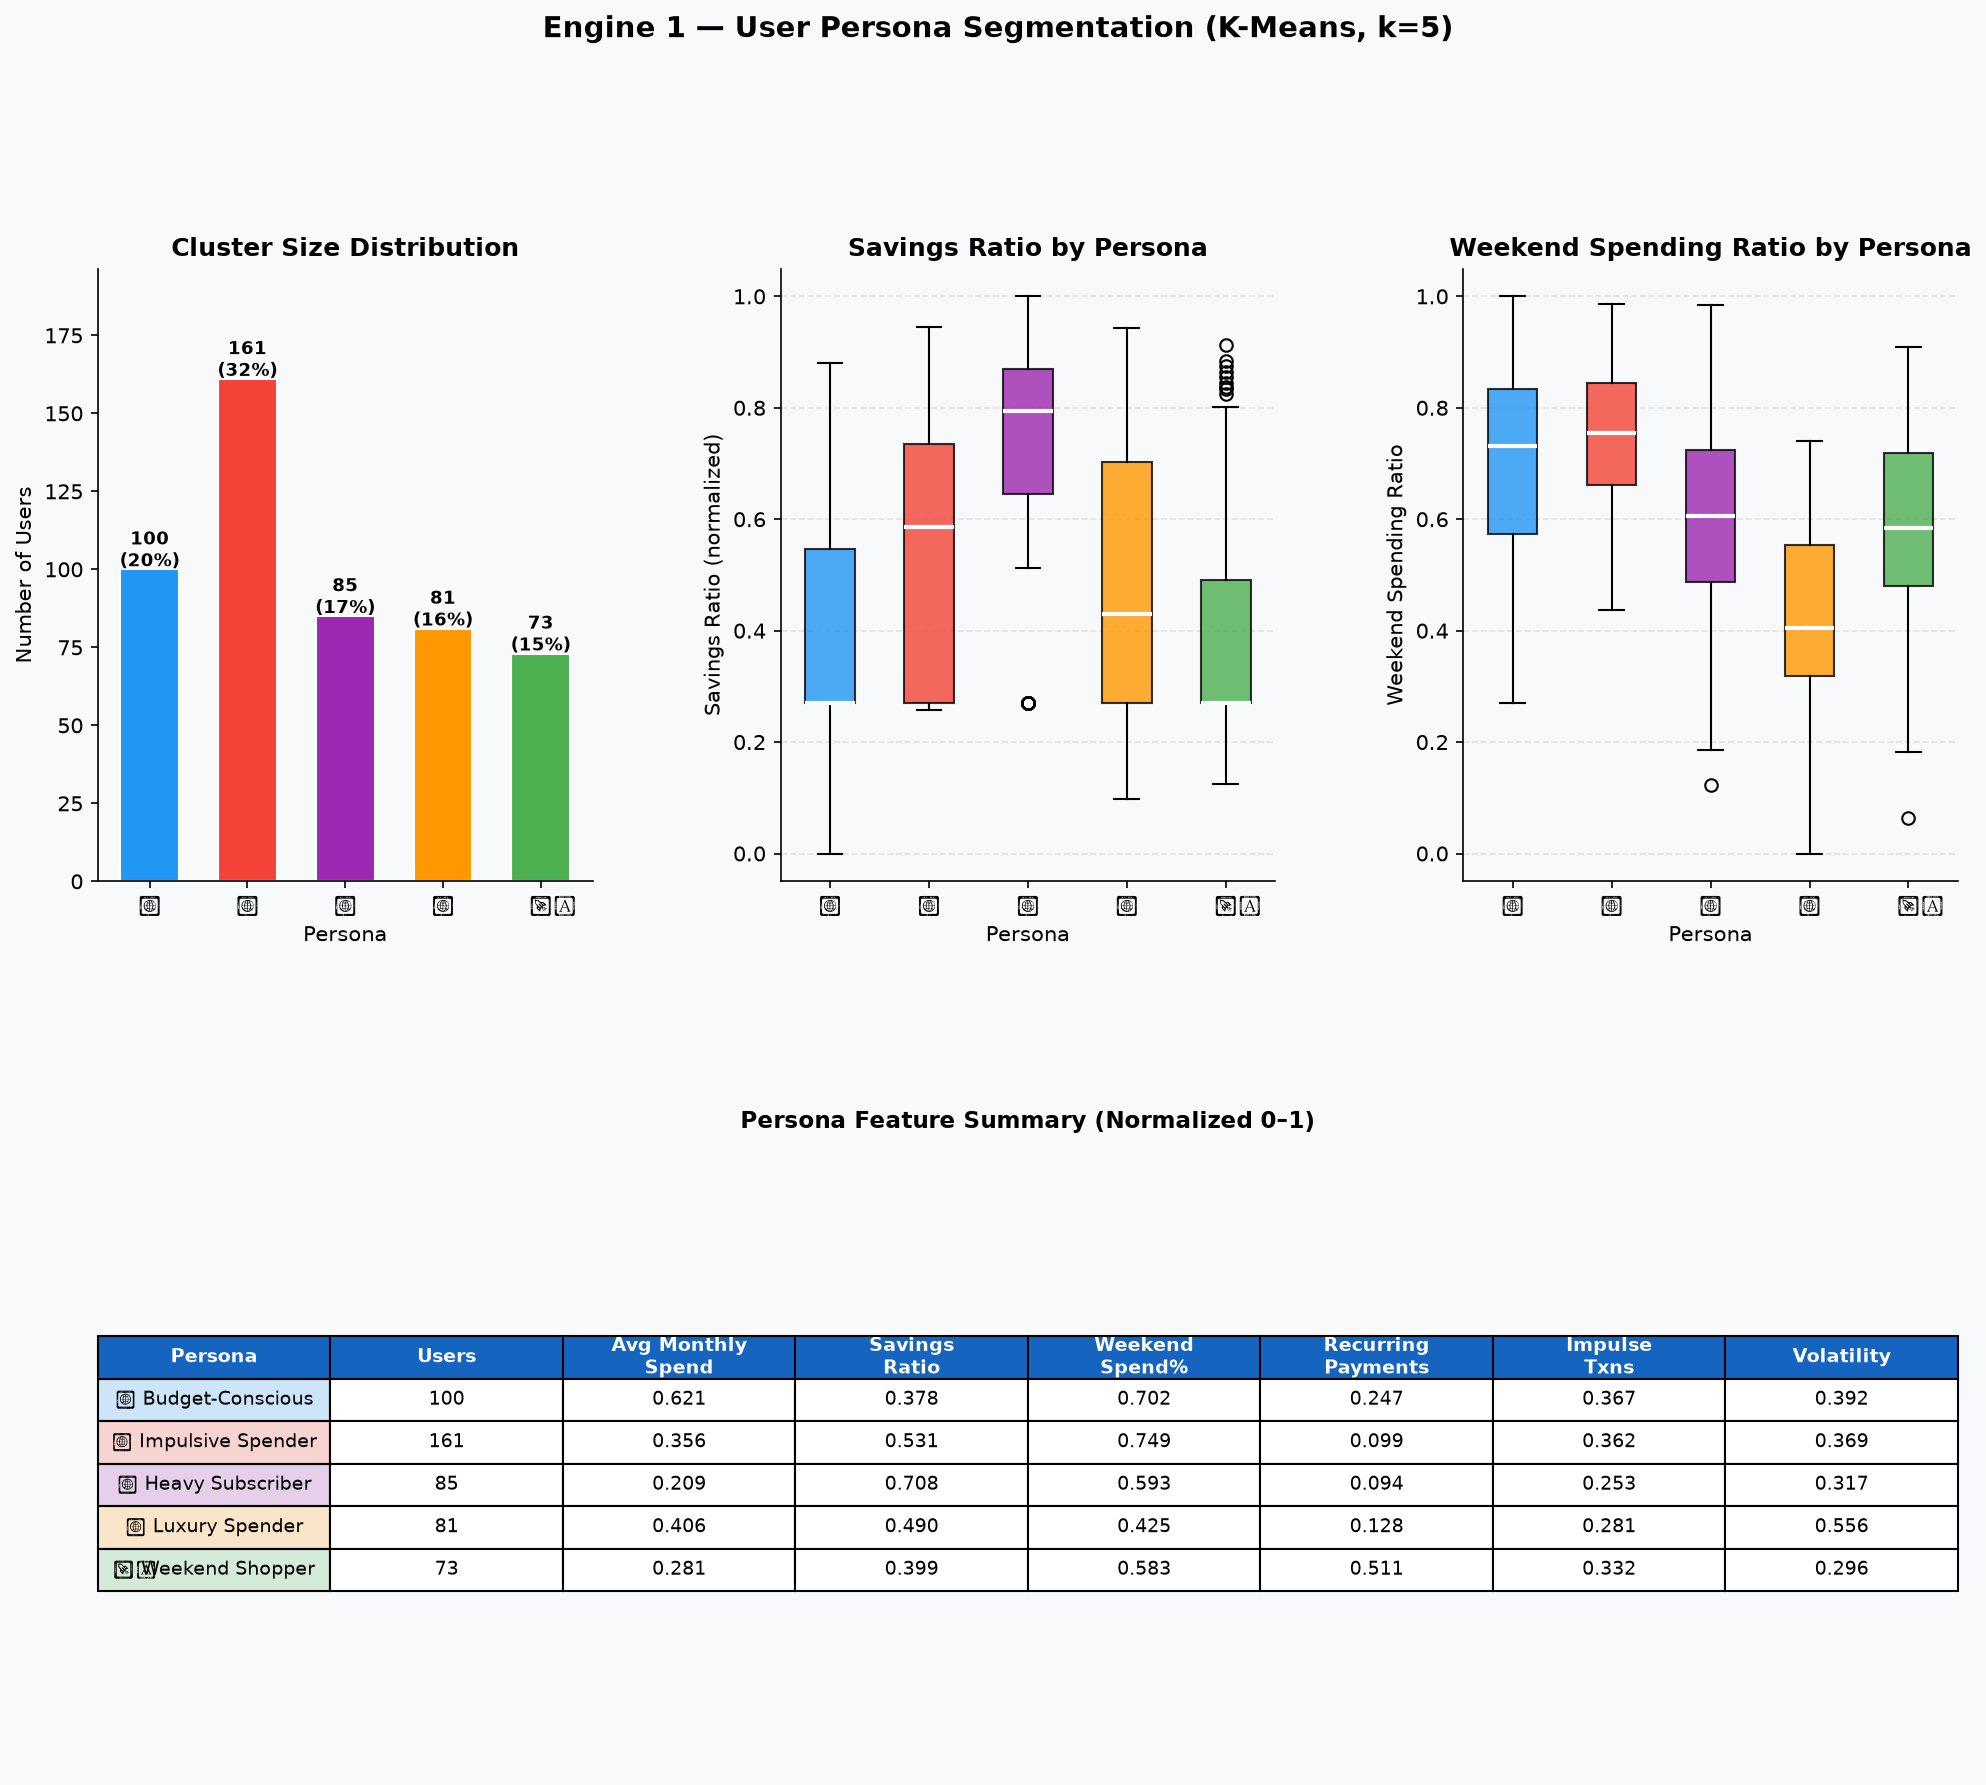

✅ Saved: outputs/eda_persona_breakdown.png

📋 AI-Generated Persona Insights:

  💰 Budget-Conscious
  Characteristic : Maintains disciplined spending habits with strong essentials focus and minimal discretionary splurges.
  Recommendation : Channel existing savings discipline into systematic investments via SIP or recurring deposits to build long-term wealth.

  🔥 Impulsive Spender
  Characteristic : Shows high weekend spending spikes and frequent large single transactions driven by impulse rather than planning.
  Recommendation : Set up weekend spending caps and real-time SMS alerts for transactions above ₹2,000 to curb impulsive behaviour.

  📺 Heavy Subscriber
  Characteristic : Accumulates multiple streaming and lifestyle subscriptions, often with overlapping services and low utilisation.
  Recommendation : Conduct a monthly subscription audit — cancel duplicate or low-use services to free ₹500–₹1,500 per month.

  💎 Luxury Spender
  Characteristic : Consistently high average transa

In [3]:
# ═══════════════════════════════════════════════════════════
# CELL 3: Persona Breakdown (Engine 1)
# ═══════════════════════════════════════════════════════════
PERSONA_META = {
    0: {'name': 'Budget-Conscious',  'emoji': '💰', 'color': '#2196F3'},
    1: {'name': 'Impulsive Spender', 'emoji': '🔥', 'color': '#F44336'},
    2: {'name': 'Heavy Subscriber',  'emoji': '📺', 'color': '#9C27B0'},
    3: {'name': 'Luxury Spender',    'emoji': '💎', 'color': '#FF9800'},
    4: {'name': 'Weekend Shopper',   'emoji': '🛍️', 'color': '#4CAF50'},
}

# Merge cluster labels into features
feat_c = features.copy()
feat_c = feat_c.join(
    clusters.set_index('user_id')[['cluster_label', 'persona_name']]
)
feat_c['persona_label'] = feat_c['cluster_label'].map(
    {k: f"{v['emoji']} {v['name']}" for k, v in PERSONA_META.items()}
)
persona_colors = [PERSONA_META[k]['color'] for k in sorted(PERSONA_META)]
persona_labels = [f"{PERSONA_META[k]['emoji']} {PERSONA_META[k]['name']}" for k in sorted(PERSONA_META)]

fig = plt.figure(figsize=(16, 13))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.38)

# ── 3a: Cluster size bar ──────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
counts = clusters['cluster_label'].value_counts().sort_index()
bars = ax1.bar([PERSONA_META[k]['emoji'] for k in counts.index],
               counts.values, color=persona_colors, edgecolor='white', width=0.6)
for bar, cnt in zip(bars, counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{cnt}\n({cnt/500*100:.0f}%)', ha='center', fontsize=8.5, fontweight='bold')
ax1.set_xlabel('Persona')
ax1.set_ylabel('Number of Users')
ax1.set_title('Cluster Size Distribution')
ax1.set_ylim(0, counts.max() * 1.22)

# ── 3b: Savings ratio box plot ────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
data_by_cluster = [feat_c[feat_c['cluster_label'] == k]['savings_ratio'].values
                   for k in sorted(PERSONA_META)]
bp = ax2.boxplot(data_by_cluster, patch_artist=True, notch=False,
                 medianprops=dict(color='white', linewidth=2))
for patch, color in zip(bp['boxes'], persona_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.80)
ax2.set_xticklabels([PERSONA_META[k]['emoji'] for k in sorted(PERSONA_META)])
ax2.set_xlabel('Persona')
ax2.set_ylabel('Savings Ratio (normalized)')
ax2.set_title('Savings Ratio by Persona')
ax2.grid(axis='y', alpha=0.3, linestyle='--')

# ── 3c: Weekend spend ratio box plot ─────────────────────
ax3 = fig.add_subplot(gs[0, 2])
data_wknd = [feat_c[feat_c['cluster_label'] == k]['weekend_spending_ratio'].values
             for k in sorted(PERSONA_META)]
bp3 = ax3.boxplot(data_wknd, patch_artist=True, notch=False,
                  medianprops=dict(color='white', linewidth=2))
for patch, color in zip(bp3['boxes'], persona_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.80)
ax3.set_xticklabels([PERSONA_META[k]['emoji'] for k in sorted(PERSONA_META)])
ax3.set_xlabel('Persona')
ax3.set_ylabel('Weekend Spending Ratio')
ax3.set_title('Weekend Spending Ratio by Persona')
ax3.grid(axis='y', alpha=0.3, linestyle='--')

# ── 3d: Summary statistics table ─────────────────────────
ax4 = fig.add_subplot(gs[1, :])
ax4.axis('off')

KEY_FEATS = ['avg_monthly_spend', 'savings_ratio', 'weekend_spending_ratio',
             'recurring_payment_count', 'impulse_transaction_count', 'spending_volatility']
TABLE_HEADERS = ['Persona', 'Users', 'Avg Monthly\nSpend', 'Savings\nRatio',
                 'Weekend\nSpend%', 'Recurring\nPayments', 'Impulse\nTxns', 'Volatility']

table_data = []
for cid, meta in PERSONA_META.items():
    grp = feat_c[feat_c['cluster_label'] == cid]
    row = [
        f"{meta['emoji']} {meta['name']}",
        f"{len(grp)}",
        f"{grp['avg_monthly_spend'].mean():.3f}",
        f"{grp['savings_ratio'].mean():.3f}",
        f"{grp['weekend_spending_ratio'].mean():.3f}",
        f"{grp['recurring_payment_count'].mean():.3f}",
        f"{grp['impulse_transaction_count'].mean():.3f}",
        f"{grp['spending_volatility'].mean():.3f}",
    ]
    table_data.append(row)

tbl = ax4.table(
    cellText=table_data,
    colLabels=TABLE_HEADERS,
    loc='center', cellLoc='center',
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.7)

for j in range(len(TABLE_HEADERS)):
    tbl[0, j].set_facecolor('#1565C0')
    tbl[0, j].set_text_props(color='white', fontweight='bold')
for i, (cid, meta) in enumerate(PERSONA_META.items(), start=1):
    tbl[i, 0].set_facecolor(meta['color'] + '33')
    for j in range(1, len(TABLE_HEADERS)):
        tbl[i, j].set_facecolor('#ffffff')

ax4.set_title('Persona Feature Summary (Normalized 0–1)', fontsize=11,
              fontweight='bold', pad=14)

fig.suptitle('Engine 1 — User Persona Segmentation (K-Means, k=5)',
             fontsize=14, fontweight='bold', y=1.01)
plt.savefig(os.path.join(NB_OUT, 'eda_persona_breakdown.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print('✅ Saved: outputs/eda_persona_breakdown.png')

# Print AI insights
print('\n📋 AI-Generated Persona Insights:')
for rec in insights:
    meta = next((m for m in PERSONA_META.values() if m['name'] == rec['persona_name']), {})
    print(f"\n  {meta.get('emoji','')} {rec['persona_name']}")
    print(f"  Characteristic : {rec.get('characteristic','')}")
    print(f"  Recommendation : {rec.get('recommendation','')}")

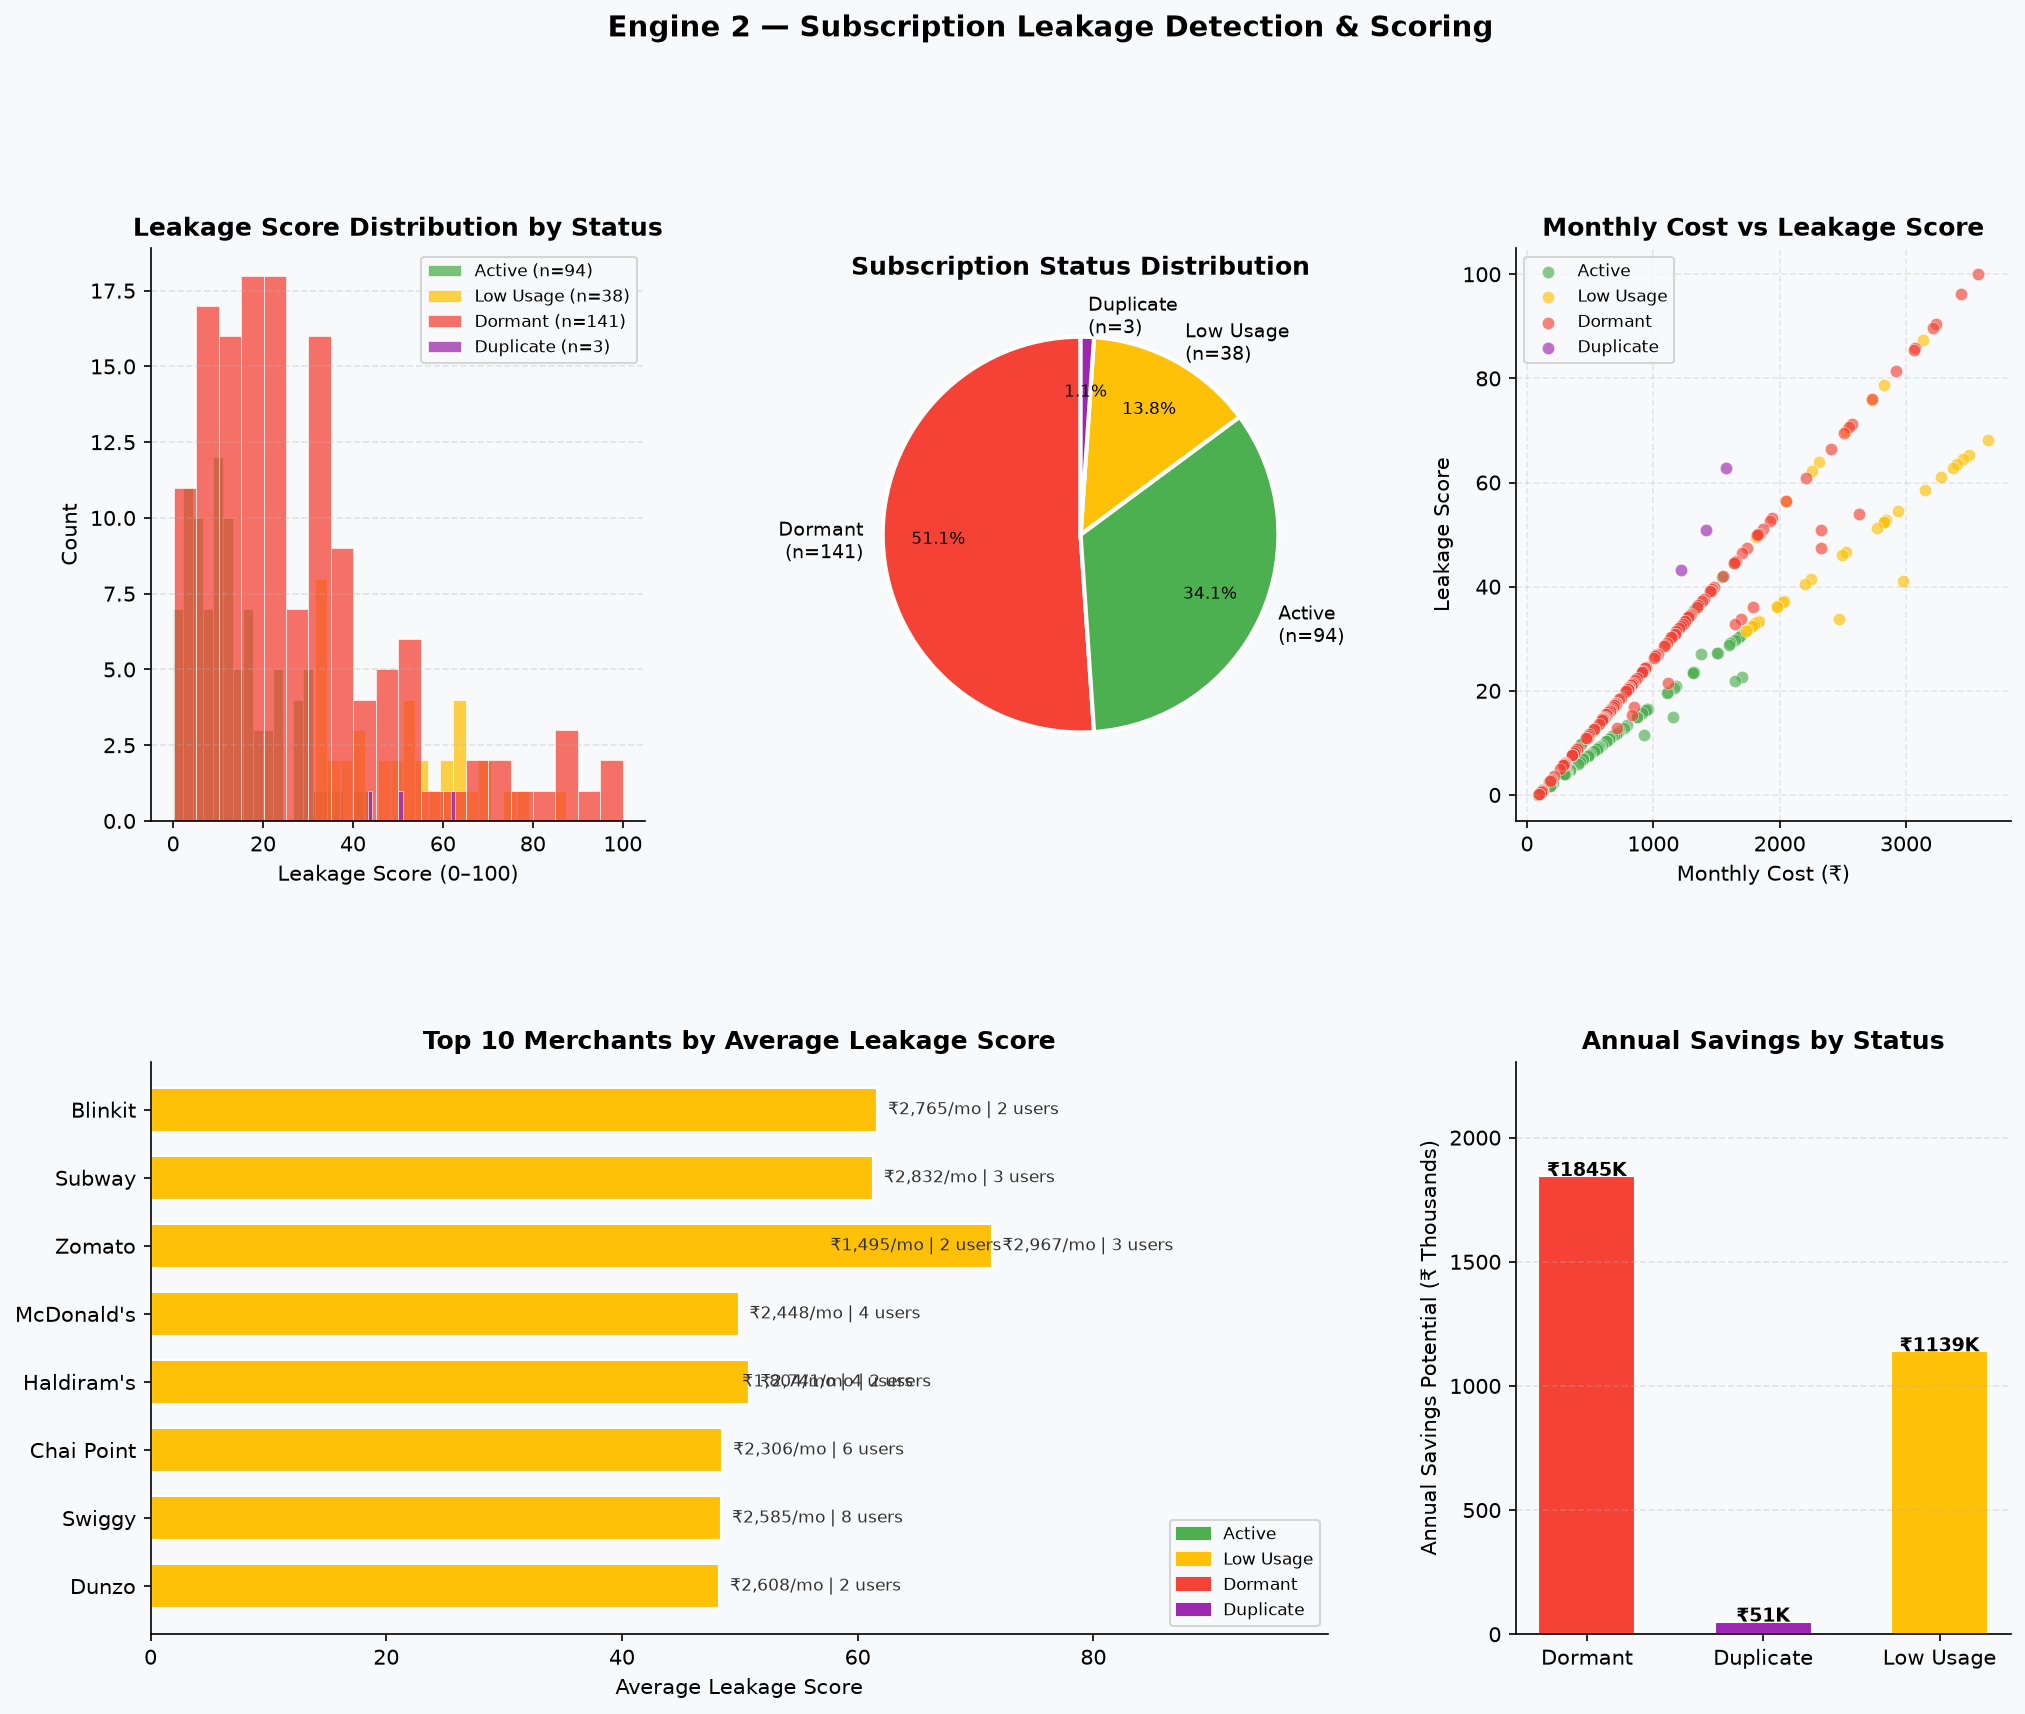

✅ Saved: outputs/eda_leakage_analysis.png

📊 Leakage Summary:
   Total recurring subscriptions  : 276
   Dormant subscriptions          : 141 (51.1%)
   High leakage (score > 60)      : 26
   Total potential annual savings : ₹3,034,883
   Avg saving per user            : ₹14,182


In [4]:
# ═══════════════════════════════════════════════════════════
# CELL 4: Leakage Analysis (Engine 2)
# ═══════════════════════════════════════════════════════════
STATUS_COLORS = {
    'Active':    '#4CAF50',
    'Low Usage': '#FFC107',
    'Dormant':   '#F44336',
    'Duplicate': '#9C27B0',
}

leakage['estimated_annual_saving'] = leakage['estimated_annual_saving'].fillna(0)

fig = plt.figure(figsize=(16, 12))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.42, wspace=0.38)

# ── 4a: Leakage score histogram by status ────────────────
ax1 = fig.add_subplot(gs[0, 0])
for status, color in STATUS_COLORS.items():
    subset = leakage[leakage['status'] == status]['leakage_score']
    if len(subset):
        ax1.hist(subset, bins=20, color=color, alpha=0.75,
                 label=f'{status} (n={len(subset)})', edgecolor='white', lw=0.4)
ax1.set_xlabel('Leakage Score (0–100)')
ax1.set_ylabel('Count')
ax1.set_title('Leakage Score Distribution by Status')
ax1.legend(fontsize=8)
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# ── 4b: Status pie chart ──────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
status_counts = leakage['status'].value_counts()
pie_colors = [STATUS_COLORS.get(s, '#888') for s in status_counts.index]
wedges, texts, autotexts = ax2.pie(
    status_counts.values,
    labels=[f'{s}\n(n={c})' for s, c in status_counts.items()],
    colors=pie_colors, autopct='%1.1f%%',
    startangle=90, pctdistance=0.72,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
)
for t in texts:      t.set_fontsize(9)
for at in autotexts: at.set_fontsize(8)
ax2.set_title('Subscription Status Distribution')

# ── 4c: Monthly cost vs leakage score scatter ────────────
ax3 = fig.add_subplot(gs[0, 2])
for status, color in STATUS_COLORS.items():
    mask = leakage['status'] == status
    ax3.scatter(leakage.loc[mask, 'monthly_amount'],
                leakage.loc[mask, 'leakage_score'],
                c=color, alpha=0.65, s=35,
                label=status, edgecolors='white', linewidths=0.3)
ax3.set_xlabel('Monthly Cost (₹)')
ax3.set_ylabel('Leakage Score')
ax3.set_title('Monthly Cost vs Leakage Score')
ax3.legend(fontsize=8)
ax3.grid(alpha=0.25, linestyle='--')

# ── 4d: Top 10 merchants by avg leakage score ────────────
ax4 = fig.add_subplot(gs[1, 0:2])
top10 = (
    leakage.groupby(['merchant_name', 'status'])
    .agg(avg_score=('leakage_score', 'mean'),
         user_count=('user_id', 'nunique'),
         avg_monthly=('monthly_amount', 'mean'))
    .reset_index()
    .sort_values('avg_score', ascending=False)
    .head(10)
    .sort_values('avg_score')
)
bar_colors_leak = [STATUS_COLORS.get(s, '#888') for s in top10['status']]
bars4 = ax4.barh(top10['merchant_name'], top10['avg_score'],
                 color=bar_colors_leak, edgecolor='white', height=0.65)
for bar, row in zip(bars4, top10.itertuples()):
    ax4.text(bar.get_width() + 0.5,
             bar.get_y() + bar.get_height()/2,
             f' ₹{row.avg_monthly:,.0f}/mo | {row.user_count} users',
             va='center', fontsize=8, color='#333')
ax4.set_xlabel('Average Leakage Score')
ax4.set_title('Top 10 Merchants by Average Leakage Score')
ax4.set_xlim(0, top10['avg_score'].max() * 1.4)
legend_patches = [plt.matplotlib.patches.Patch(color=v, label=k)
                  for k, v in STATUS_COLORS.items()]
ax4.legend(handles=legend_patches, fontsize=8, loc='lower right')

# ── 4e: Annual savings potential bar ─────────────────────
ax5 = fig.add_subplot(gs[1, 2])
savings_by_status = (
    leakage[leakage['status'] != 'Active']
    .groupby('status')['estimated_annual_saving'].sum()
    .reset_index()
)
bar_colors5 = [STATUS_COLORS.get(s, '#888') for s in savings_by_status['status']]
bars5 = ax5.bar(savings_by_status['status'],
                savings_by_status['estimated_annual_saving'] / 1e3,
                color=bar_colors5, edgecolor='white', width=0.55)
for bar, val in zip(bars5, savings_by_status['estimated_annual_saving'] / 1e3):
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'₹{val:.0f}K', ha='center', fontsize=9, fontweight='bold')
ax5.set_ylabel('Annual Savings Potential (₹ Thousands)')
ax5.set_title('Annual Savings by Status')
ax5.set_ylim(0, savings_by_status['estimated_annual_saving'].max() / 1e3 * 1.25)
ax5.grid(axis='y', alpha=0.3, linestyle='--')

fig.suptitle('Engine 2 — Subscription Leakage Detection & Scoring',
             fontsize=14, fontweight='bold', y=1.01)
plt.savefig(os.path.join(NB_OUT, 'eda_leakage_analysis.png'),
            dpi=150, bbox_inches='tight')
plt.show()

total_saving = leakage['estimated_annual_saving'].sum()
dormant_n    = (leakage['status'] == 'Dormant').sum()
high_leak_n  = (leakage['leakage_score'] > 60).sum()
print(f'✅ Saved: outputs/eda_leakage_analysis.png')
print(f'\n📊 Leakage Summary:')
print(f'   Total recurring subscriptions  : {len(leakage):,}')
print(f'   Dormant subscriptions          : {dormant_n} ({dormant_n/len(leakage)*100:.1f}%)')
print(f'   High leakage (score > 60)      : {high_leak_n}')
print(f'   Total potential annual savings : ₹{total_saving:,.0f}')
print(f'   Avg saving per user            : ₹{total_saving/leakage["user_id"].nunique():,.0f}')

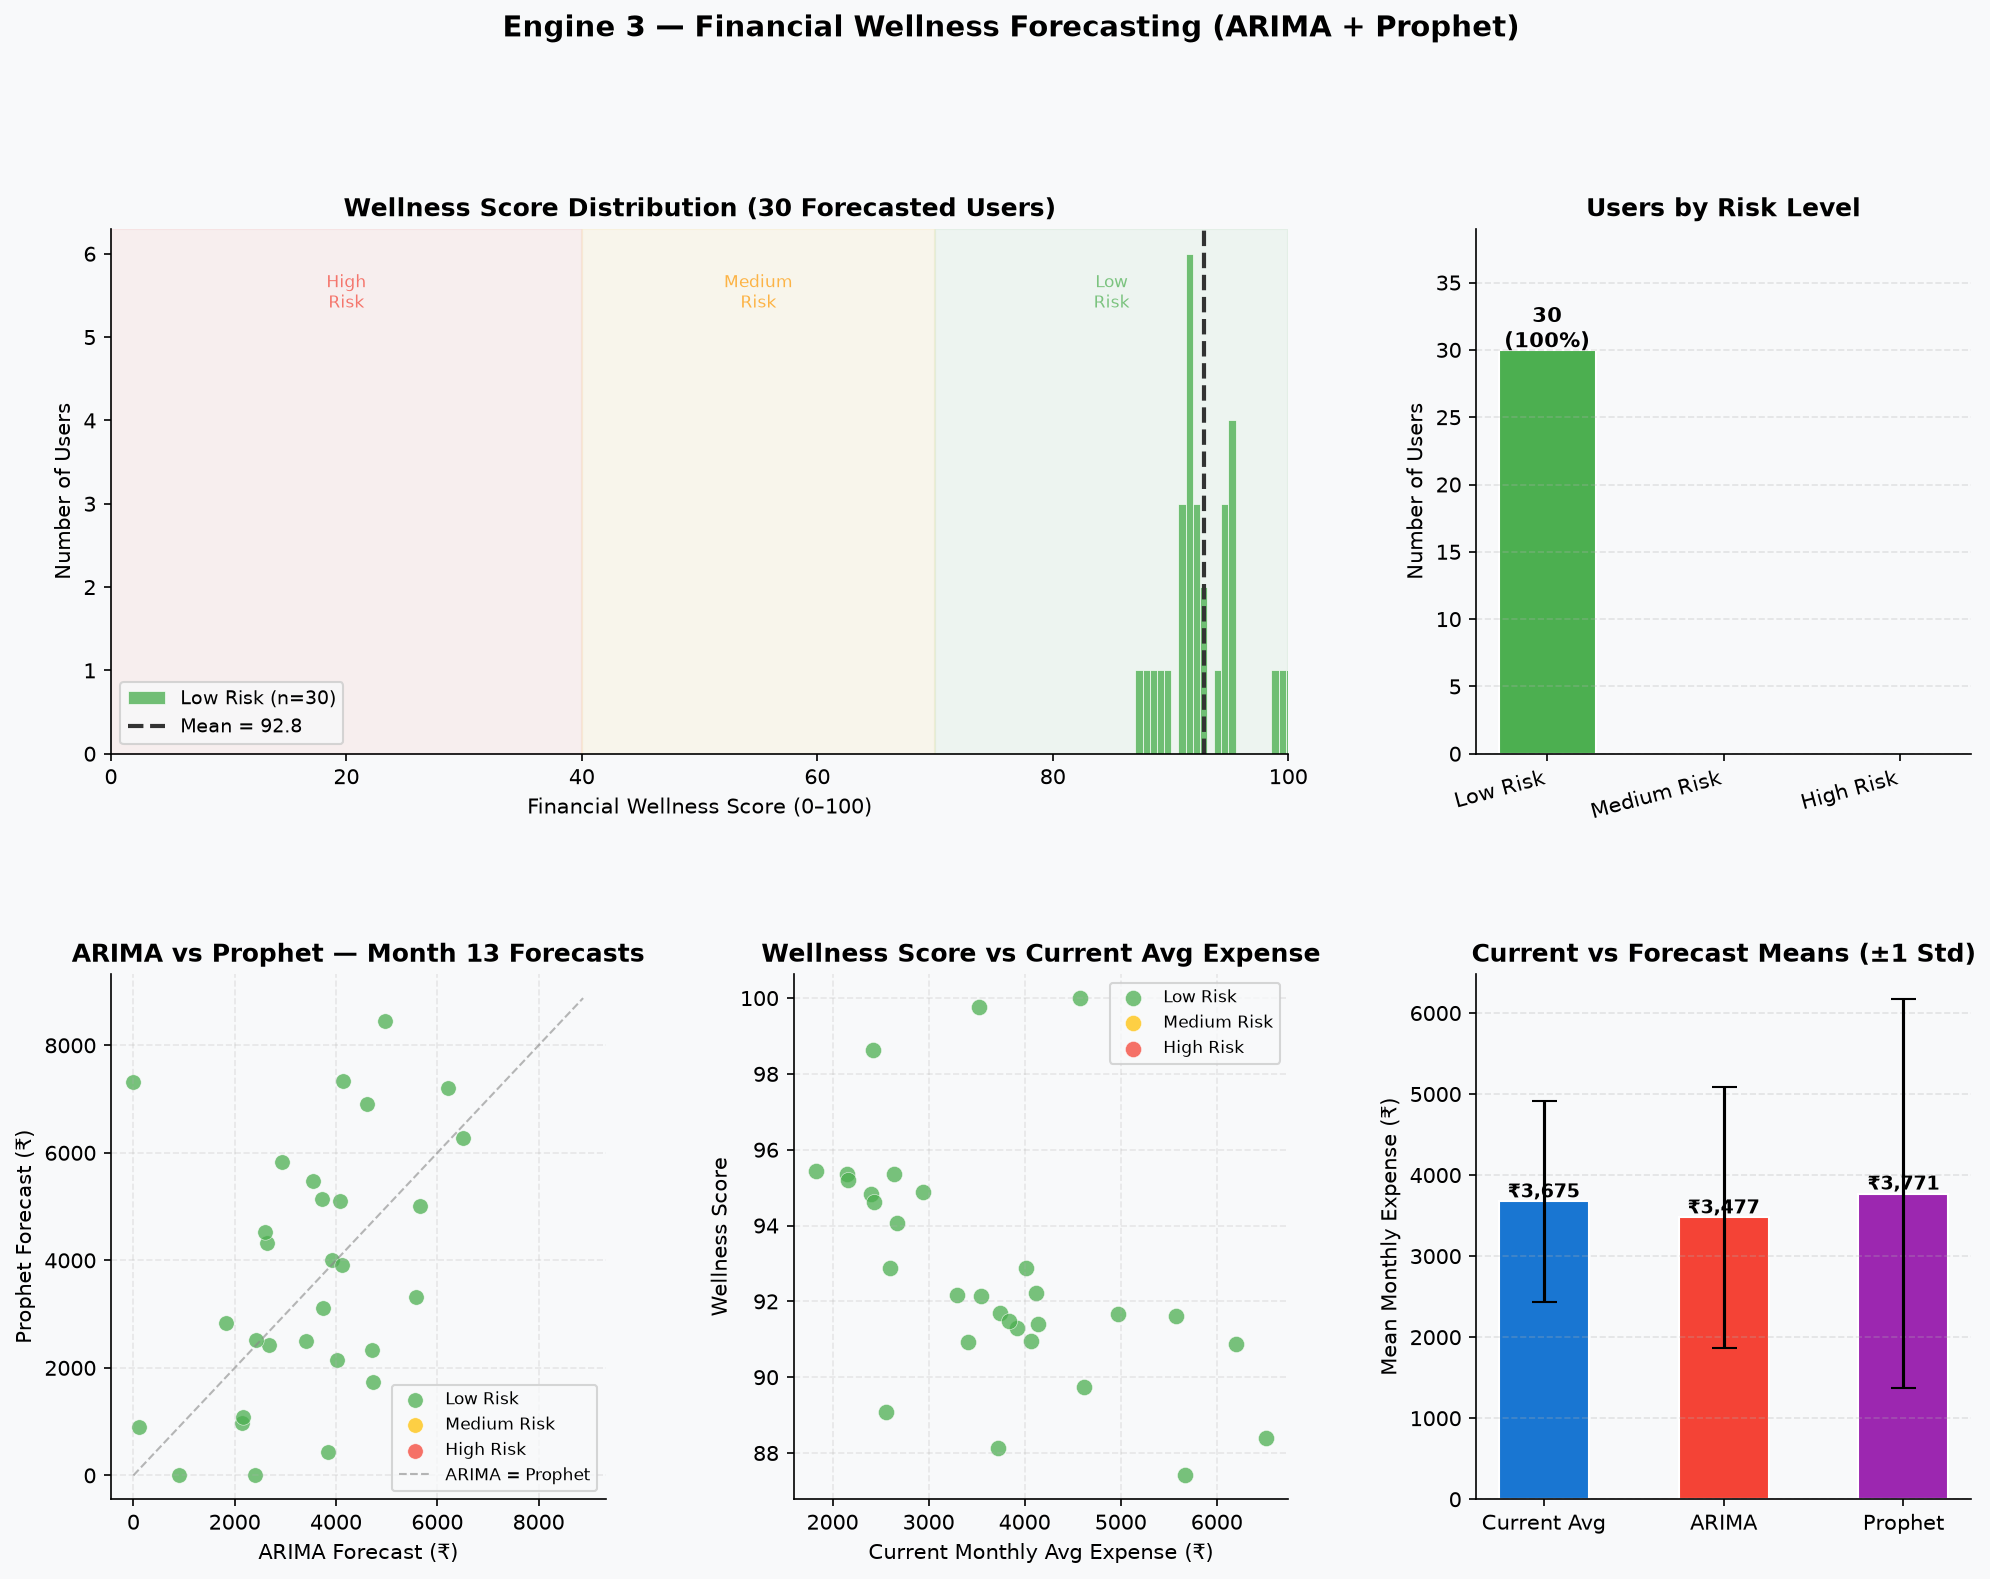

✅ Saved: outputs/eda_wellness_distribution.png

📊 Wellness Forecast Summary:
       wellness_score  forecasted_month13_arima  forecasted_month13_prophet
count           30.00                     30.00                       30.00
mean            92.84                   3477.27                     3771.45
std              3.16                   1611.08                     2398.75
min             87.41                      0.00                        0.00
25%             91.04                   2468.88                     2186.42
50%             92.15                   3733.23                     3607.62
75%             94.87                   4494.02                     5395.80
max            100.00                   6509.81                     8455.54


In [5]:
# ═══════════════════════════════════════════════════════════
# CELL 5: Wellness Distribution (Engine 3)
# ═══════════════════════════════════════════════════════════
RISK_COLORS = {
    'Low Risk':    '#4CAF50',
    'Medium Risk': '#FFC107',
    'High Risk':   '#F44336',
}

fig = plt.figure(figsize=(16, 11))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.42, wspace=0.38)

# ── 5a: Wellness score histogram by risk ─────────────────
ax1 = fig.add_subplot(gs[0, 0:2])
bins = np.linspace(forecast['wellness_score'].min() - 1,
                   forecast['wellness_score'].max() + 1, 25)
for risk, color in RISK_COLORS.items():
    subset = forecast[forecast['risk_level'] == risk]['wellness_score']
    if len(subset):
        ax1.hist(subset, bins=bins, color=color, alpha=0.78,
                 label=f'{risk} (n={len(subset)})', edgecolor='white', lw=0.4)
mean_ws = forecast['wellness_score'].mean()
ax1.axvline(mean_ws, color='#333', lw=2, linestyle='--',
            label=f'Mean = {mean_ws:.1f}')
# Colored zone bands
ax1.axvspan(0,  40, alpha=0.06, color='#F44336', zorder=0)
ax1.axvspan(40, 70, alpha=0.06, color='#FFC107', zorder=0)
ax1.axvspan(70, 100,alpha=0.06, color='#4CAF50', zorder=0)
ax1.text(20, ax1.get_ylim()[1]*0.85 if ax1.get_ylim()[1] > 0 else 0.5,
         'High\nRisk', ha='center', color='#F44336', fontsize=8, alpha=0.7)
ax1.text(55, ax1.get_ylim()[1]*0.85 if ax1.get_ylim()[1] > 0 else 0.5,
         'Medium\nRisk', ha='center', color='#FF9800', fontsize=8, alpha=0.7)
ax1.text(85, ax1.get_ylim()[1]*0.85 if ax1.get_ylim()[1] > 0 else 0.5,
         'Low\nRisk', ha='center', color='#4CAF50', fontsize=8, alpha=0.7)
ax1.set_xlabel('Financial Wellness Score (0–100)')
ax1.set_ylabel('Number of Users')
ax1.set_title('Wellness Score Distribution (30 Forecasted Users)')
ax1.legend(fontsize=9)
ax1.set_xlim(0, 100)

# ── 5b: Risk count bar ───────────────────────────────────
ax2 = fig.add_subplot(gs[0, 2])
risk_counts = forecast['risk_level'].value_counts()
ordered_risks = ['Low Risk', 'Medium Risk', 'High Risk']
counts_ordered = [risk_counts.get(r, 0) for r in ordered_risks]
colors_ordered = [RISK_COLORS[r] for r in ordered_risks]
bars2 = ax2.bar(ordered_risks, counts_ordered, color=colors_ordered,
                edgecolor='white', width=0.55)
for bar, cnt in zip(bars2, counts_ordered):
    if cnt > 0:
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
                 f'{cnt}\n({cnt/len(forecast)*100:.0f}%)',
                 ha='center', fontsize=10, fontweight='bold')
ax2.set_ylabel('Number of Users')
ax2.set_title('Users by Risk Level')
ax2.set_ylim(0, max(counts_ordered) * 1.3 if max(counts_ordered) > 0 else 5)
ax2.set_xticklabels(ordered_risks, rotation=15, ha='right')
ax2.grid(axis='y', alpha=0.3, linestyle='--')

# ── 5c: ARIMA vs Prophet scatter ─────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
for risk, color in RISK_COLORS.items():
    mask = forecast['risk_level'] == risk
    ax3.scatter(
        forecast.loc[mask, 'forecasted_month13_arima'],
        forecast.loc[mask, 'forecasted_month13_prophet'],
        c=color, alpha=0.75, s=55, label=risk,
        edgecolors='white', linewidths=0.3,
    )
ax_max = max(forecast['forecasted_month13_arima'].max(),
             forecast['forecasted_month13_prophet'].max()) * 1.05
ax3.plot([0, ax_max], [0, ax_max], '--', color='#888', lw=1, alpha=0.6,
         label='ARIMA = Prophet')
ax3.set_xlabel('ARIMA Forecast (₹)')
ax3.set_ylabel('Prophet Forecast (₹)')
ax3.set_title('ARIMA vs Prophet — Month 13 Forecasts')
ax3.legend(fontsize=8)
ax3.grid(alpha=0.25, linestyle='--')

# ── 5d: Wellness vs current monthly avg ──────────────────
ax4 = fig.add_subplot(gs[1, 1])
for risk, color in RISK_COLORS.items():
    mask = forecast['risk_level'] == risk
    ax4.scatter(
        forecast.loc[mask, 'current_monthly_avg'],
        forecast.loc[mask, 'wellness_score'],
        c=color, alpha=0.75, s=60, label=risk,
        edgecolors='white', linewidths=0.3,
    )
ax4.set_xlabel('Current Monthly Avg Expense (₹)')
ax4.set_ylabel('Wellness Score')
ax4.set_title('Wellness Score vs Current Avg Expense')
ax4.legend(fontsize=8)
ax4.grid(alpha=0.25, linestyle='--')

# ── 5e: Model comparison bar ─────────────────────────────
ax5 = fig.add_subplot(gs[1, 2])
model_means = pd.DataFrame({
    'Model': ['Current Avg', 'ARIMA', 'Prophet'],
    'Mean (₹)': [
        forecast['current_monthly_avg'].mean(),
        forecast['forecasted_month13_arima'].mean(),
        forecast['forecasted_month13_prophet'].mean(),
    ],
    'Std (₹)': [
        forecast['current_monthly_avg'].std(),
        forecast['forecasted_month13_arima'].std(),
        forecast['forecasted_month13_prophet'].std(),
    ]
})
bars5 = ax5.bar(model_means['Model'], model_means['Mean (₹)'],
                yerr=model_means['Std (₹)'],
                color=['#1976D2', '#F44336', '#9C27B0'],
                edgecolor='white', width=0.5,
                capsize=6, error_kw={'linewidth': 1.5})
for bar, val in zip(bars5, model_means['Mean (₹)']):
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
             f'₹{val:,.0f}', ha='center', fontsize=9, fontweight='bold')
ax5.set_ylabel('Mean Monthly Expense (₹)')
ax5.set_title('Current vs Forecast Means (±1 Std)')
ax5.grid(axis='y', alpha=0.3, linestyle='--')

fig.suptitle('Engine 3 — Financial Wellness Forecasting (ARIMA + Prophet)',
             fontsize=14, fontweight='bold', y=1.01)
plt.savefig(os.path.join(NB_OUT, 'eda_wellness_distribution.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print('✅ Saved: outputs/eda_wellness_distribution.png')

print(f'\n📊 Wellness Forecast Summary:')
print(forecast[['wellness_score', 'forecasted_month13_arima', 'forecasted_month13_prophet']]
      .describe().round(2).to_string())

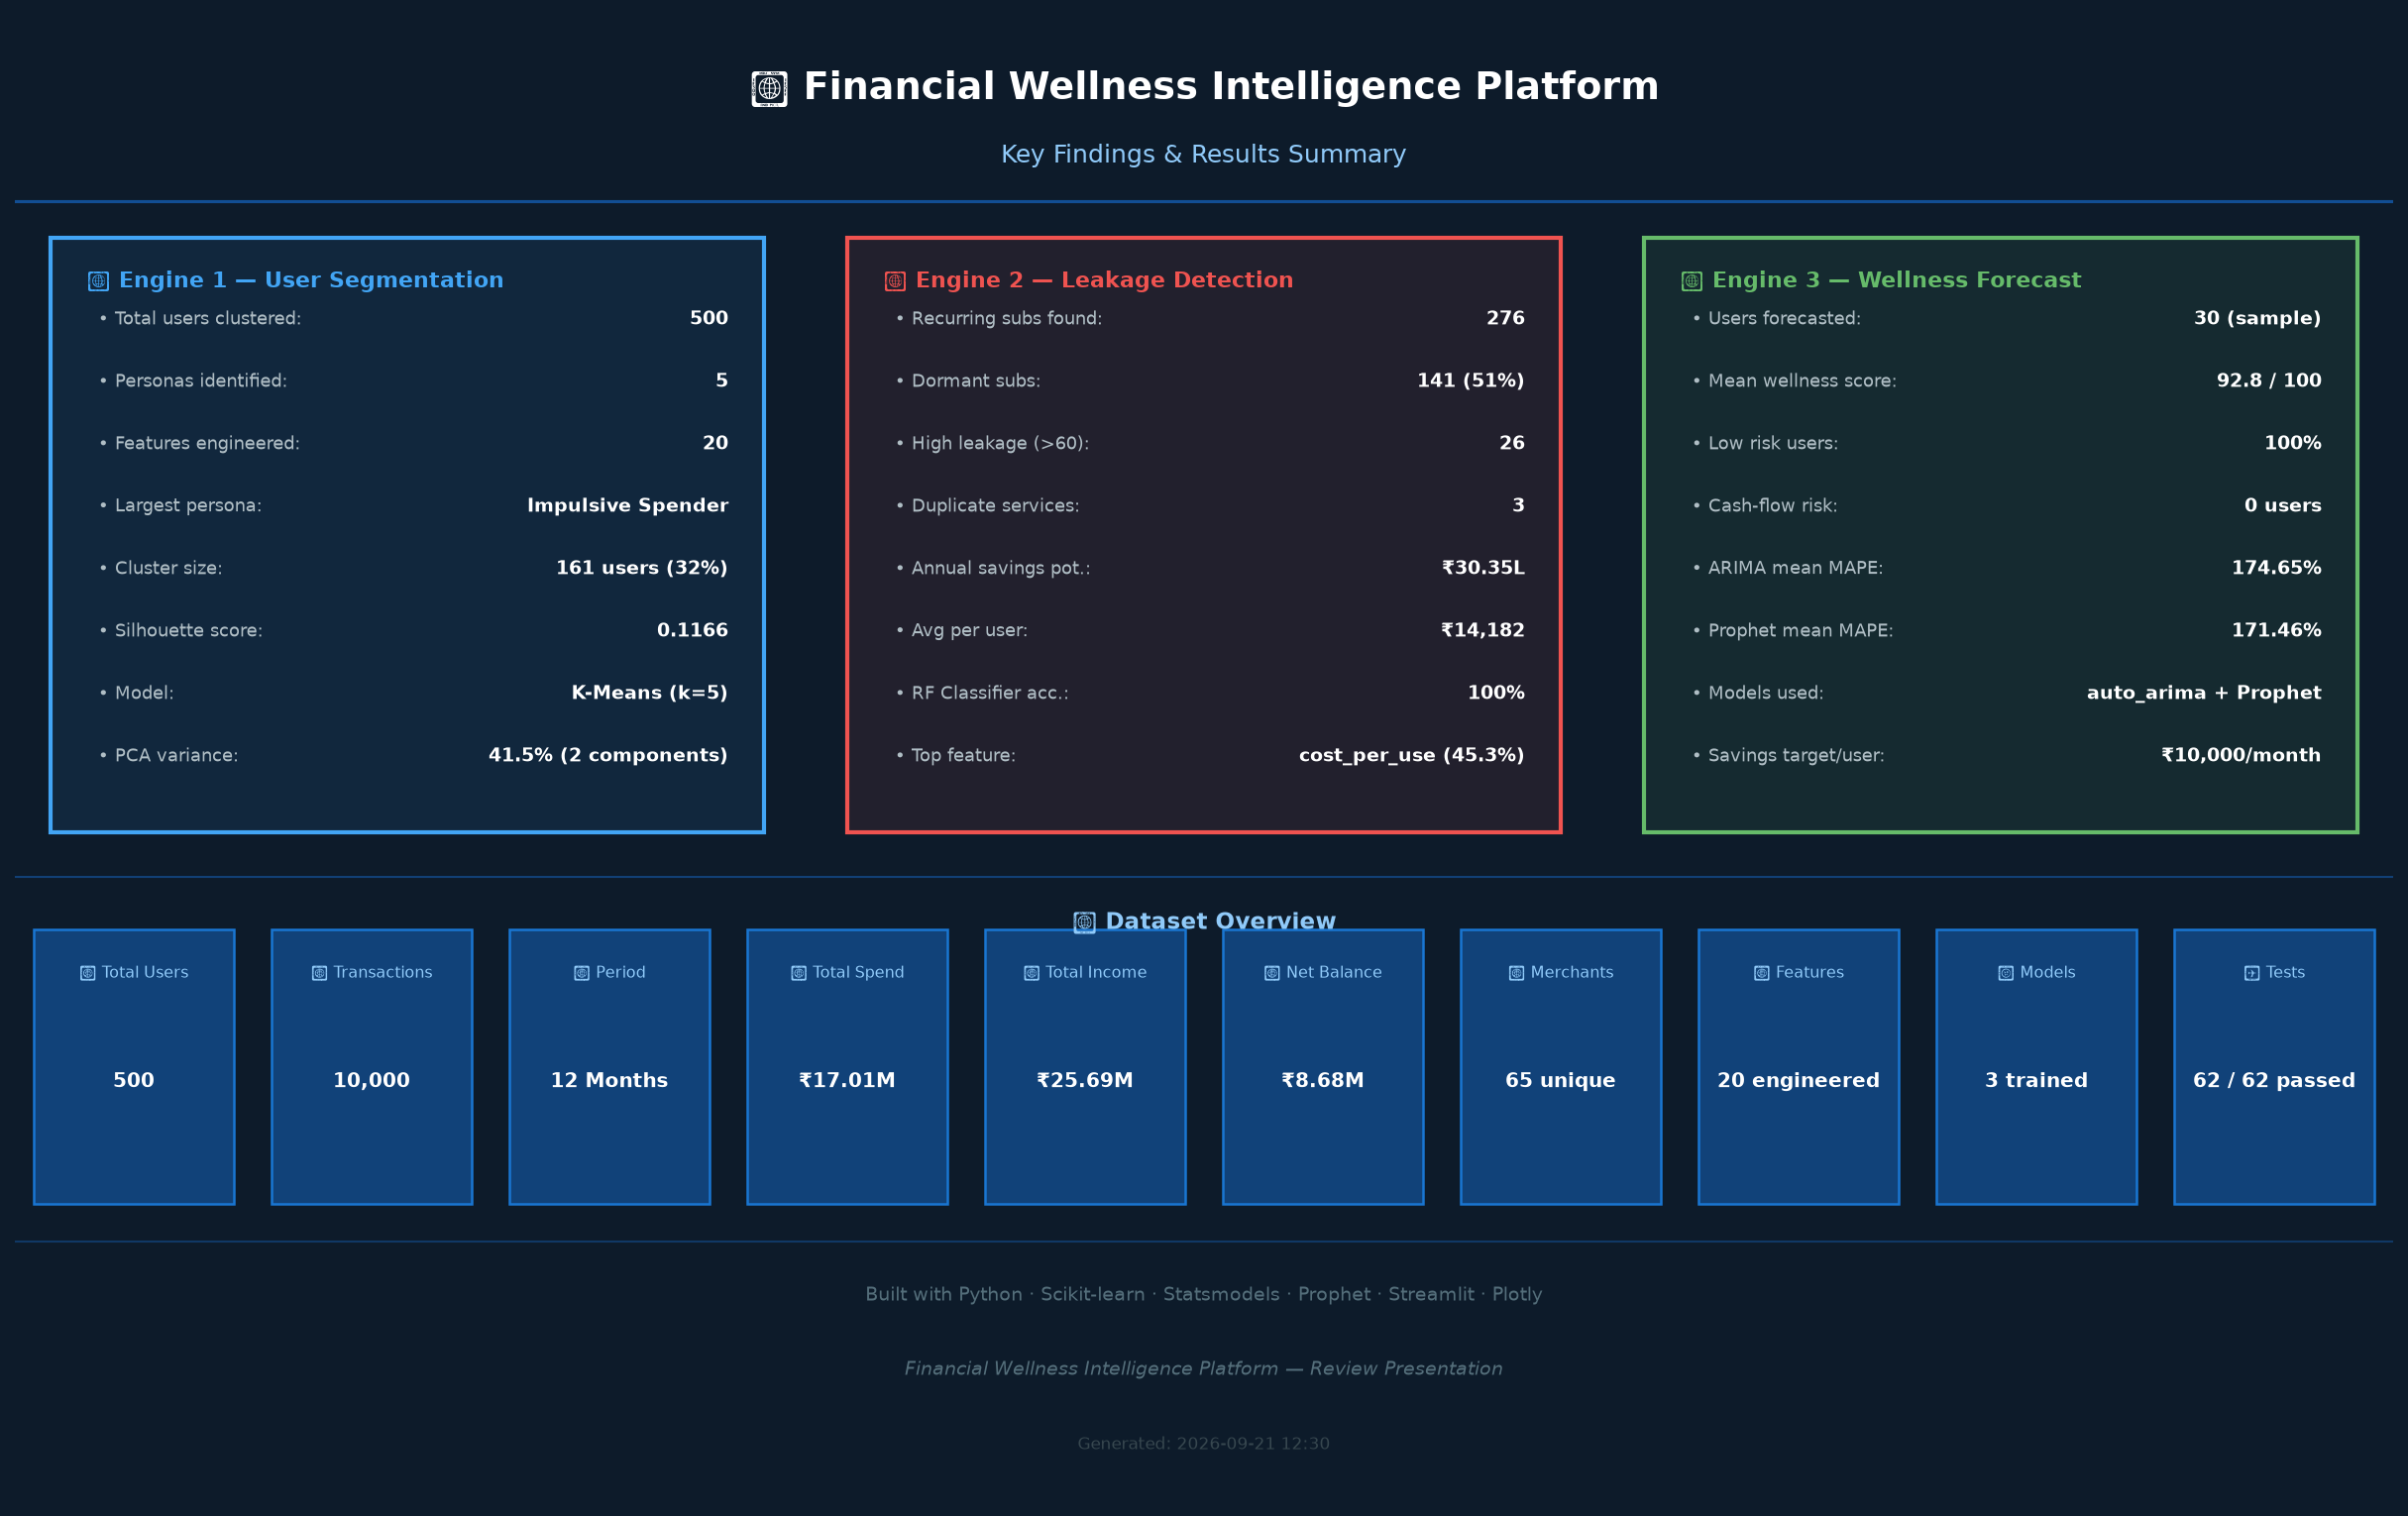

✅ Saved: outputs/eda_key_findings.png

════════════════════════════════════════════════════════════
  📋 ALL EDA OUTPUTS SAVED:
  • outputs/eda_spending_analysis.png
  • outputs/eda_persona_breakdown.png
  • outputs/eda_leakage_analysis.png
  • outputs/eda_wellness_distribution.png
  • outputs/eda_key_findings.png
════════════════════════════════════════════════════════════

  🎉 EDA & Results Notebook Complete!
  Financial Wellness Engine — Ready for Review Presentation


In [6]:
# ═══════════════════════════════════════════════════════════
# CELL 6: Key Findings Summary
# ═══════════════════════════════════════════════════════════
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(16, 10))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis('off')
fig.patch.set_facecolor('#0D1B2A')
ax.set_facecolor('#0D1B2A')

def txt(x, y, s, **kw):
    ax.text(x, y, s, transform=ax.transData, **kw)

# ── Title ────────────────────────────────────────────────
txt(5, 9.5, '💰 Financial Wellness Intelligence Platform',
    ha='center', va='center', fontsize=18, fontweight='bold', color='#FFFFFF')
txt(5, 9.05, 'Key Findings & Results Summary',
    ha='center', va='center', fontsize=12, color='#90CAF9')

# ── Divider ───────────────────────────────────────────────
ax.axhline(8.75, color='#1565C0', linewidth=1.5, alpha=0.7)

# ── Section helper ────────────────────────────────────────
def section_box(x, y, w, h, title, color, items):
    rect = plt.Rectangle((x, y), w, h, linewidth=2, edgecolor=color,
                          facecolor=color + '18', zorder=2)
    ax.add_patch(rect)
    txt(x + 0.15, y + h - 0.22, title,
        fontsize=10.5, fontweight='bold', color=color, va='top')
    for i, (label, value) in enumerate(items):
        yp = y + h - 0.55 - i * 0.42
        txt(x + 0.2,  yp, f'• {label}:', fontsize=8.5, color='#B0BEC5', va='center')
        txt(x + w - 0.15, yp, value, fontsize=9, fontweight='bold',
            color='#FFFFFF', va='center', ha='right')

# Compute values
total_income   = txn[txn['transaction_type']=='Credit']['amount'].sum()
total_expense  = txn[txn['transaction_type']=='Debit']['amount'].sum()
net_balance    = total_income - total_expense
largest_persona = clusters['persona_name'].value_counts().idxmax()
largest_count   = clusters['persona_name'].value_counts().max()
silhouette      = 0.1166
total_saving    = leakage['estimated_annual_saving'].sum()
dormant_pct     = (leakage['status']=='Dormant').sum() / len(leakage) * 100
mean_ws_val     = forecast['wellness_score'].mean()
low_risk_pct    = (forecast['risk_level']=='Low Risk').sum() / len(forecast) * 100

# ── Engine 1 Box ─────────────────────────────────────────
section_box(0.15, 4.5, 3.0, 4.0,
    '🎯 Engine 1 — User Segmentation',
    '#42A5F5',
    [
        ('Total users clustered',  '500'),
        ('Personas identified',    '5'),
        ('Features engineered',    '20'),
        ('Largest persona',        f'{largest_persona}'),
        ('Cluster size',           f'{largest_count} users (32%)'),
        ('Silhouette score',       f'{silhouette:.4f}'),
        ('Model',                  'K-Means (k=5)'),
        ('PCA variance',           '41.5% (2 components)'),
    ]
)

# ── Engine 2 Box ─────────────────────────────────────────
section_box(3.5, 4.5, 3.0, 4.0,
    '🔍 Engine 2 — Leakage Detection',
    '#EF5350',
    [
        ('Recurring subs found',   f'{len(leakage):,}'),
        ('Dormant subs',           f'{(leakage["status"]=="Dormant").sum()} ({dormant_pct:.0f}%)'),
        ('High leakage (>60)',     f'{(leakage["leakage_score"]>60).sum()}'),
        ('Duplicate services',     f'{(leakage["status"]=="Duplicate").sum()}'),
        ('Annual savings pot.',    f'₹{total_saving/1e5:.2f}L'),
        ('Avg per user',           f'₹{total_saving/leakage["user_id"].nunique():,.0f}'),
        ('RF Classifier acc.',     '100%'),
        ('Top feature',            'cost_per_use (45.3%)'),
    ]
)

# ── Engine 3 Box ─────────────────────────────────────────
section_box(6.85, 4.5, 3.0, 4.0,
    '📈 Engine 3 — Wellness Forecast',
    '#66BB6A',
    [
        ('Users forecasted',       '30 (sample)'),
        ('Mean wellness score',    f'{mean_ws_val:.1f} / 100'),
        ('Low risk users',         f'{low_risk_pct:.0f}%'),
        ('Cash-flow risk',         '0 users'),
        ('ARIMA mean MAPE',        '174.65%'),
        ('Prophet mean MAPE',      '171.46%'),
        ('Models used',            'auto_arima + Prophet'),
        ('Savings target/user',    '₹10,000/month'),
    ]
)

# ── Dataset stats bottom bar ──────────────────────────────
ax.axhline(4.2, color='#1565C0', linewidth=1, alpha=0.5)
txt(5, 3.85, '📊 Dataset Overview', ha='center', fontsize=11,
    fontweight='bold', color='#90CAF9')

bottom_stats = [
    ('👥 Total Users',     '500'),
    ('📋 Transactions',    '10,000'),
    ('📅 Period',          '12 Months'),
    ('💳 Total Spend',     f'₹{total_expense/1e6:.2f}M'),
    ('💰 Total Income',    f'₹{total_income/1e6:.2f}M'),
    ('📈 Net Balance',     f'₹{net_balance/1e6:.2f}M'),
    ('🏪 Merchants',       '65 unique'),
    ('📂 Features',        '20 engineered'),
    ('🤖 Models',          '3 trained'),
    ('✅ Tests',           '62 / 62 passed'),
]
n = len(bottom_stats)
for i, (label, value) in enumerate(bottom_stats):
    x_pos = 0.5 + i * (9.0 / (n - 1))
    rect = plt.Rectangle((x_pos - 0.42, 2.0), 0.84, 1.85,
                          facecolor='#1565C088', edgecolor='#1976D2',
                          linewidth=1.2, zorder=2)
    ax.add_patch(rect)
    txt(x_pos, 3.55, label,   ha='center', va='center',
        fontsize=7.5, color='#90CAF9')
    txt(x_pos, 2.82, value,   ha='center', va='center',
        fontsize=9.5, fontweight='bold', color='#FFFFFF')

# ── Footer ────────────────────────────────────────────────
ax.axhline(1.75, color='#1565C0', linewidth=1, alpha=0.4)
txt(5, 1.35,
    'Built with Python · Scikit-learn · Statsmodels · Prophet · Streamlit · Plotly',
    ha='center', fontsize=9, color='#546E7A')
txt(5, 0.85,
    'Financial Wellness Intelligence Platform — Review Presentation',
    ha='center', fontsize=9, color='#546E7A', style='italic')
txt(5, 0.35,
    f'Generated: {pd.Timestamp.now().strftime("%Y-%m-%d %H:%M")}',
    ha='center', fontsize=8, color='#37474F')

plt.tight_layout(pad=0)
plt.savefig(os.path.join(NB_OUT, 'eda_key_findings.png'),
            dpi=150, bbox_inches='tight', facecolor='#0D1B2A')
plt.show()
print('✅ Saved: outputs/eda_key_findings.png')
print()
print('═'*60)
print('  📋 ALL EDA OUTPUTS SAVED:')
print('  • outputs/eda_spending_analysis.png')
print('  • outputs/eda_persona_breakdown.png')
print('  • outputs/eda_leakage_analysis.png')
print('  • outputs/eda_wellness_distribution.png')
print('  • outputs/eda_key_findings.png')
print('═'*60)
print()
print('  🎉 EDA & Results Notebook Complete!')
print('  Financial Wellness Engine — Ready for Review Presentation')